# The Subset Sum problem
In this notebook, we will describe and step through a Qiskit circuit implementing an algorithm to solve the subset sum problem.
Specifically we are given a finite set $S=\{x_0, \dots, x_{n-1}\}$ of positive integers and a positive integer target $t$. The aim is to find a subset of $F\subseteq S$ such that,
$$ t = \sum_{x\in F} x.$$
There are $2^n$ possible subsets of $S$ and if one tries a brute force method, classically the time complexity would be $O(2^n)$. We will show how in the quantum setting, with the help of Grover's algorithm, we can achieve a query complexity of $O(2^{n/2})$.
In this implementation, we can encode each subset as a length $n$ bitstring, where the $k$th bit (counting from the right), tells us if the $x_k$ is in our given subset. For example if $S=\{x_0,x_1,x_2\}$, then the bitstring corresponding to the subset $\{x_1,x_2\}$ is "$110$". Note that if elements are repeated in our list, then some subsets may contain the same elements. For purposes of this implementation they are considered different subsets since they have different corresponding bitstring representations. This encoding will be used in one of the quantum registers in our implementation.

Here is a outline of the algorithm:
1. Construct a phase oracle that when given a sublist (in the form of a bitstring described above), it flips the phase if the sum of the sublist is exactly the target and it does nothing otherwise.
2. Apply Grover's algorithm using the oracle above.
3. Measure and check if the produced answer is in fact a solution.
4. Repeat with steps 2 and 3 until we find a solution or the budget is expended.

Below are the imports required for this notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Math
from qiskit.quantum_info import Statevector

from quantum_subset_sum.subset_sum import *

## Constructing the Phase Oracle

We have two qubit registers that we will use. The first is what we will call the index register of length $n$, which encodes information about the subsets in exactly the way described above. The second is what we will call the sum register, to store the sum of a given sublist. This register consists of ancilla qubits, and will be uncomputed every grover iteration. This register will have $\left\lceil \log_2 \left(1+ \sum_{x\in S} x \right) \right\rceil$ qubits and will be initialized with all $0$s. Throughout when we consider both sets of qubits above, we will write $\ket{b}\ket{a}$ where $\ket{a}$ corresponds to the index register and $\ket{b}$ to the sum register.

### Controlled Draper's Adder
The aim of this subsection is to produce a reversible map:
$$ \ket{0}\ket{a}\to \ket{\sum a_i x_i}\ket{a}. $$
The idea is very similar to the circuit used in Draper's adder for a fixed constant. There are two key differences:
1. There are multiple additions. One could chain multiple Draper adders together, but since each adder starts with a QFT and ends with an IQFT, they cancel each other out. It is more efficient to do all the phase changes corresponding to each value in the Fourier basis..
2. Addition is conditional on a corresponding control qubit in the index register. This is solved by using a controlled phase gate instead of a phase gate, where the control qubit is the corresponding qubit in the index register.

An implementation of this in Qiskit as a gate is given below:

In [2]:
controlled_draper_adder??

Signature: controlled_draper_adder(values: list[int], num_of_sum_qubits: int) -> qiskit.circuit.gate.Gate
Source:   
def controlled_draper_adder(values: list[int], num_of_sum_qubits: int) -> Gate:
    """Constructs a Draper adder that adds fixed classical integers to a sum register, conditionally on an index register.

    Args:
        values: The classical integers to be added to the sum register.
        num_of_sum_qubits: Size of the sum register.
    Returns:
        A controlled Draper's adder (with fixed constants) gate. The registers are ordered (the least significant bit first) with the index register first then the sum register.
    """
    num_of_control_qubits = len(values)
    index_register = QuantumRegister(size=num_of_control_qubits, name="Index Register")
    sum_register = QuantumRegister(size=num_of_sum_qubits, name="Sum Register")

    circuit = QuantumCircuit(index_register, sum_register)

    # Apply a qft to the sum register to transform it to the Fourier basis
 

The QFT and IQFT gates were implemented using the code from the labs.

In [3]:
qft??

Signature: qft(num_of_qubits: int) -> qiskit.circuit.gate.Gate
Source:   
def qft(num_of_qubits: int) -> Gate:
    """Constructs a QFT gate with n qubits. Assumed that n is positive. This code snippet is taken from lab 2.

    Args:
        num_of_qubits: Number of qubits to be used in the gate. Assumed to be a positive integer.

    Returns:
        A QFT gate with n qubits.
    """
    circuit = QuantumCircuit(num_of_qubits, name="QFT")
    for j in range(num_of_qubits // 2):
        circuit.swap(j, num_of_qubits - 1 - j)
    for j in range(num_of_qubits):
        circuit.h(j)
        for ell in range(j + 1, num_of_qubits):
            circuit.cp(np.pi / 2 ** (ell - j), j, ell)

    circuit = circuit.to_gate()
    circuit.label = "QFT"
    return circuit
File:      ~/Documents/Quantum Computing Bootcamp/Mini Projects/Mini Project 1/quantum-subset-sum/src/quantum_subset_sum/subset_sum.py
Type:      function

In [4]:
iqft??

Signature: iqft(num_of_qubits: int) -> qiskit.circuit.gate.Gate
Source:   
def iqft(num_of_qubits: int) -> Gate:
    """Constructs an inverse QFT gate with n qubits. Assumed that n is positive. This code snippet is taken from lab 2.

    Args:
        num_of_qubits: Number of qubits to be used in the gate. Assumed to be a positive integer.

    Returns:
        An inverse QFT gate with n qubits.
    """
    circuit = QuantumCircuit(num_of_qubits, name="IQFT")
    for j in reversed(range(num_of_qubits)):
        for ell in reversed(range(j + 1, num_of_qubits)):
            circuit.cp(-np.pi / 2 ** (ell - j), j, ell)
        circuit.h(j)
    for j in reversed(range(num_of_qubits // 2)):
        circuit.swap(j, num_of_qubits - 1 - j)

    circuit = circuit.to_gate()
    circuit.label = "IQFT"
    return circuit
File:      ~/Documents/Quantum Computing Bootcamp/Mini Projects/Mini Project 1/quantum-subset-sum/src/quantum_subset_sum/subset_sum.py
Type:      function

Here is what the controlled Draper adder circuit looks like with the list [1,2,3].

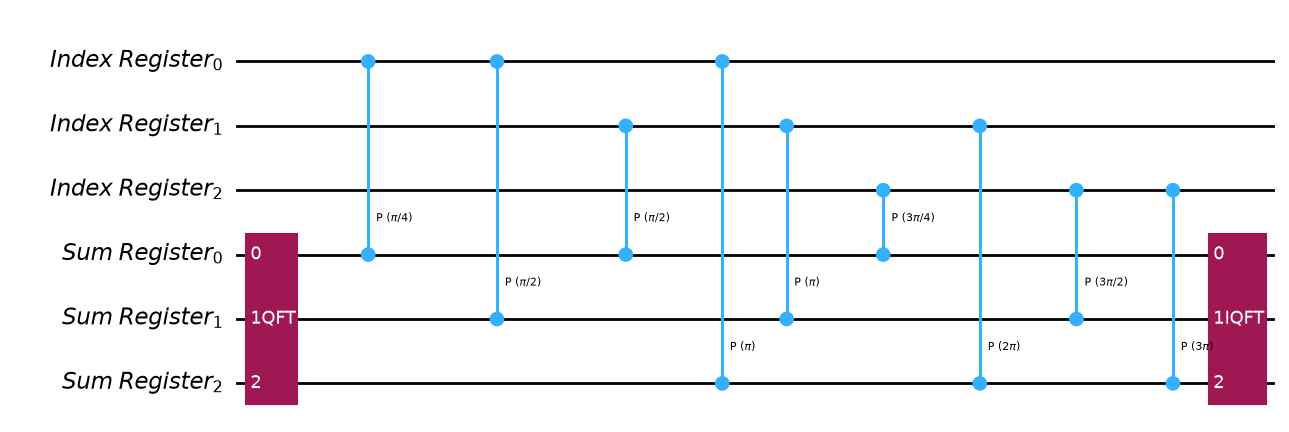

In [5]:
values = [1, 2, 3]

# Construct the circuit for the list above
num_of_sum_qubits = int(np.ceil(np.log2(sum(values) + 1)))
adder = controlled_draper_adder(values, num_of_sum_qubits)
num_of_control_qubits = len(values)
index_register = QuantumRegister(size=num_of_control_qubits, name="Index Register")
sum_register = QuantumRegister(size=num_of_sum_qubits, name="Sum Register")
ad_circuit = QuantumCircuit(index_register, sum_register)
ad_circuit.append(adder, index_register[:] + sum_register[:])

display(ad_circuit.decompose().draw("mpl"))

We now show this on the simple initial statevector $\ket{000}\ket{101}$. This corresponds to the subset $\{1, 3\}$. The sum of this subset is 4, hence our expected output should be $\ket{100}\ket{101} = \ket{100101}$.

In [6]:
sum_state = "0" * num_of_sum_qubits
state = Statevector.from_label(sum_state + "101")
print("Initial State:")
display(state.draw("latex"))

print("Evolved State:")
state = state.evolve(ad_circuit)
display(state.draw("latex"))

Initial State:


<IPython.core.display.Latex object>

Evolved State:


<IPython.core.display.Latex object>

More tests are included in the test_subset_sum.py file, where this is checked more thoroughly.

### Comparator and Phase Kickback
Given that we have computed the sum, we now want to compare the sum to the target and mark the states where the sum is exactly the target. The idea is as follows:
1. Convert the target integer into a binary bitstring, call it $s$ of the same length as the sum register
2. Apply $X$ gates to qubits in the sum register where the corresponding bit in $s$ is 0. This means that the sum register is in the state $\ket{11\dots 1}$ if and only if the sum was the target.
3. Flip the phase if the sum register $\ket{11\dots 1}$.
4. Apply the $X$ gates as in step 2 again to reverse the operation. This allows us to uncompute the sum later.

We explain how do step 3 without an extra anilla bit. The idea is to apply a multicontrolled $Z$ gate, with control qubits as the sum register and target qubit any fixed qubit in the index register (we take the first qubit for simplicity), followed by a multicontrolled $Z$ gate conjugated by $X$ gates on the target qubit. The first MCZ gate flips the phase if and only if the sum register is in the state $\ket{11\dots 1}$ and the first index register qubit is 1. The second MCZ conjugated by $X$ gates on the first index register qubit flips the phase if and only if the sum register is in the state $\ket{11\dots 1}$ and the first index register qubit is 1. In all cases this operation flips the phase if and only if the sum register is in the state $\ket{11\dots 1}$.

The implementation of this comparator and phase kickback is below. Note that an MCZ gate is the same as a MCX gate complemented by Hadamard gates. This is used below since mcz gates are not a method the QuantumCircuit class. Qiskit does have other libraries that implement MCZ gates but this is done to keep the imports minimal and so that the number of gates is easier to count.

In [7]:
phase_kickback??

Signature:
phase_kickback(
    target: int,
    sum_register_length: int,
    index_register_length: int,
) -> qiskit.circuit.gate.Gate
Source:   
def phase_kickback(
    target: int, sum_register_length: int, index_register_length: int
) -> Gate:
    """Constructs a gate that flips the phase of vectors that have the target sum.
    Args:
        target: The target sum. Assumed that target is positive and less that 2^sum_register_length.
        sum_register_length: Size of the sum register.
        index_register_length: Size of the index register.
    Returns:
        A phase kickback gate for the given target sum. The registers are ordered (the least significant bit first) with the index register first then the sum register.
    """
    target_bitstring = f"{target:b}".zfill(sum_register_length)

    sum_register = QuantumRegister(sum_register_length)
    index_register = QuantumRegister(index_register_length)

    circuit = QuantumCircuit(index_register, sum_register)

    # Flip t

We verify the phase kickback circuit for a very simple example. Suppose the target is $5$, the sum register and index register have 3 qubits each. We verify the output when the sum register is the target, i.e. 5, and not the target.

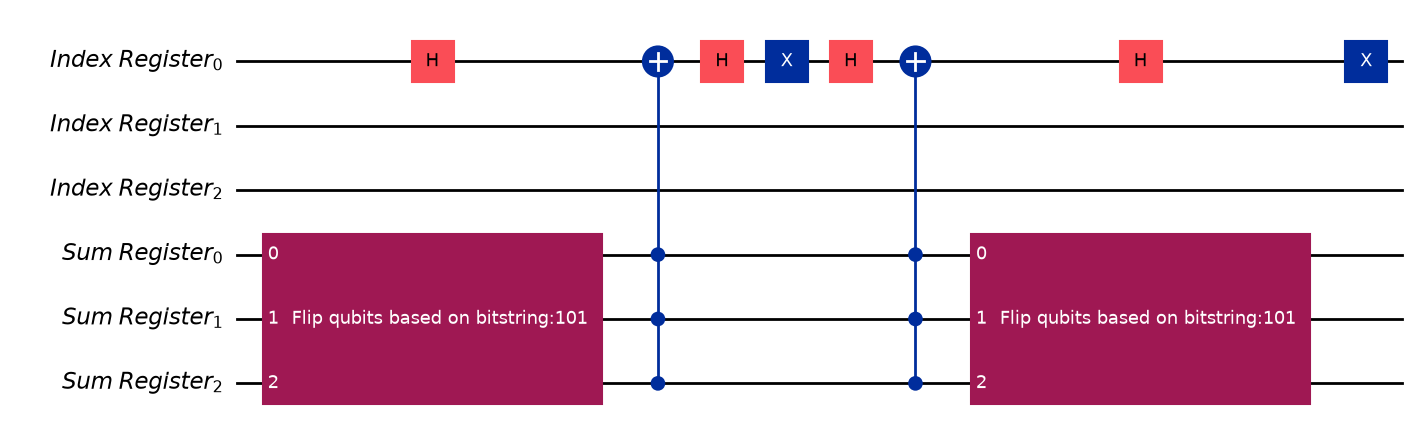

This is the case when the sum register (the first 3 qubits in the ket) is 5, i.e. the target.


<IPython.core.display.Math object>


This is the case when the sum register (the first 3 qubits in the ket) is 2, i.e. not the target.


<IPython.core.display.Math object>

In [8]:
target = 5

sum_register_length = 3
index_register_length = 3

sum_register = QuantumRegister(sum_register_length, name="Sum Register")
index_register = QuantumRegister(index_register_length, name="Index Register")

pk_circuit = QuantumCircuit(index_register, sum_register)
pk_circuit.append(
    phase_kickback(target, sum_register_length, index_register_length),
    index_register[:] + sum_register[:],
)

display(pk_circuit.decompose().draw("mpl"))

# This is the case when the sum register is the target
sum_string = "101"
index_string = "110"
state = Statevector.from_label(sum_string + index_string)
evolved_state = state.evolve(pk_circuit)
print(
    "This is the case when the sum register (the first 3 qubits in the ket) is 5, i.e. the target."
)
display(
    Math(
        state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

print()

# This is the case when the sum register is not the target
sum_string = "010"
index_string = "110"
state = Statevector.from_label(sum_string + index_string)
evolved_state = state.evolve(pk_circuit)
print(
    "This is the case when the sum register (the first 3 qubits in the ket) is 2, i.e. not the target."
)
display(
    Math(
        state.draw("latex").data[:-2]
        + " \\mapsto"
        + evolved_state.draw("latex").data[2:]
    )
)

The helper function flip_bits, which makes a gate for steps 2 and 4 above, is shown below:

In [9]:
flip_bits??

Signature: flip_bits(bitstring: str)
Source:   
def flip_bits(bitstring: str):
    """A gate that applies an X gate to certain qubits.
    Args:
        bitstring: Bit string that controls which qubit indices have an X gate applied to.
    Returns:
        A gate that applies an X gate to qubits where the bit in the corresponding bitstring is 0. This is to be used on the sum register (the ancilla register).
    """

    register = QuantumRegister(len(bitstring))
    circuit = QuantumCircuit(register)

    for i, bit in enumerate(bitstring):
        # Apply an x gate if the corresponding bit in the bitstring is 0
        if bit == "0":
            # Note the first element in the register is the MSB, hence the reversal of the index below.
            circuit.x(register[len(bitstring) - 1 - i])

    circuit = circuit.to_gate()
    circuit.label = f"Flip qubits based on bitstring:{bitstring}"

    return circuit
File:      ~/Documents/Quantum Computing Bootcamp/Mini Projects/Mini Project 1

We use the same example as above. When the target is $5$, i.e. bitstring "101" and the sum register has 3 qubits we get the following circuit:

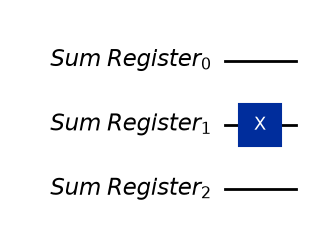

In [10]:
sum_register = QuantumRegister(size=3, name="Sum Register")

flip_gate = flip_bits("101")

f_circuit = QuantumCircuit(sum_register)
f_circuit.append(flip_gate, sum_register)

display(f_circuit.decompose().draw("mpl"))

### Phase Oracle
Now we combine all of the above to make the phase oracle. The steps are as follows:
1. Use the controlled Draper adder to compute the sum.
2. Apply a phase flip to mark the states where the sum is the same as the target.
3. Uncompute the sum. This is done by applying the controlled Draper adder but with the negative of the elements in the set instead.

Note that we need to uncompute the sum so that the Grover diffuser step works. Here is the implementation:

In [11]:
phase_oracle??

Signature: phase_oracle(input_list: list[int], target: int) -> qiskit.circuit.gate.Gate
Source:   
def phase_oracle(input_list: list[int], target: int) -> Gate:
    """Constructs a phase oracle circuit for the subset sum problem.
    Args:
        input_list: The original set given. All the elements are assumed to be positive integers.
        target: The target sum. Assumed to be positive.
    Returns:
        A phase oracle gate for the subset sum problem for the given set and target. The registers are ordered (the least significant bit first) with the index register first then the sum register.
    """
    n = len(input_list)
    total = sum(input_list)
    sum_register_length = int(np.ceil(np.log2(total + 1)))

    sum_register = QuantumRegister(size=sum_register_length, name="Sum Register")
    index_register = QuantumRegister(size=n, name="Index")

    circuit = QuantumCircuit(index_register, sum_register)

    # Compute all subset sums.
    controlled_draper_adder_gate = control

We manually verify the phase oracle with the set $\{1,1,1\}$ and target $2$. We check every possible index register configuration and we verify that the sum register is uncomputed, i.e $\ket{00\dots 0}$ after.

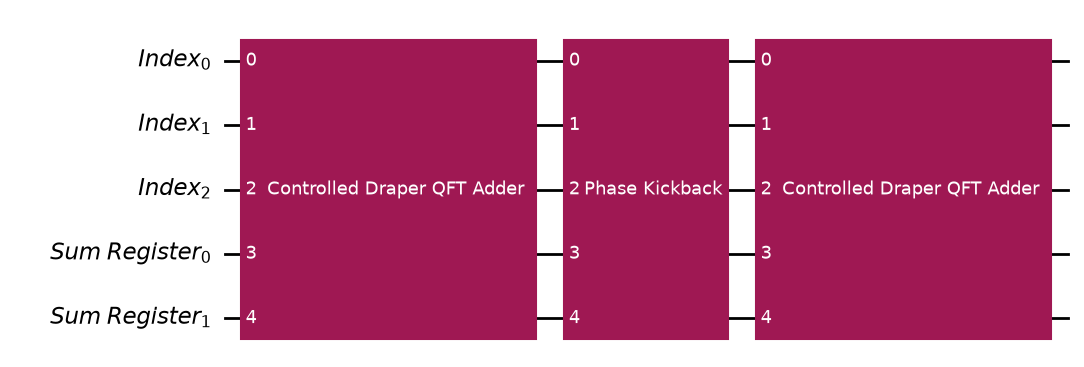

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [12]:
input_list = [1, 1, 1]
target = 2

n = len(input_list)
total = sum(input_list)
sum_register_length = int(np.ceil(np.log2(total + 1)))

sum_register = QuantumRegister(size=sum_register_length, name="Sum Register")
index_register = QuantumRegister(size=n, name="Index")

po_circuit = QuantumCircuit(index_register, sum_register)
po_circuit.append(phase_oracle(input_list, target), index_register[:] + sum_register[:])

display(po_circuit.decompose().draw("mpl"))

sum_string = "0" * sum_register_length

# Construct and evolve all possible index register states with sum register starting at |00>.
for i in range(2**n):
    index_string = f"{i:b}".zfill(n)
    state = Statevector.from_label(sum_string + index_string)
    evolved_state = state.evolve(po_circuit)

    display(
        Math(
            state.draw("latex").data[:-2]
            + " \\mapsto"
            + evolved_state.draw("latex").data[2:]
        )
    )

Above the sum register, is the 2 qubits in the ket from the left. We verify that above the sum is uncomputed, that is the sum register is returned to $\ket{00}$.

Note that the above states have their phase flipped if and only if the sum of the corresponding subset is 2. In our specific example this happens if and only if the subset has two elements, i.e. there are two 1s in the the rightmost digits in the ket.

Hence we verify that for this small example the phase oracle works as intended. More tests are included in the test suite.

## Grover Iterations
### Implementation
The Grover's iteration and diffuser circuit implementations are shown below:

In [13]:
grover_diffuser??

Signature: grover_diffuser(num_of_qubits: int) -> qiskit.circuit.gate.Gate
Source:   
def grover_diffuser(num_of_qubits: int) -> Gate:
    """Constructs a Grover diffuser gate for n qubits.
    Args:
        num_of_qubits: Number of qubits. Assumed to be positive.
    Returns:
        A Grover diffuser gate for n qubits (to be used on the index register).
    """
    index_register = QuantumRegister(size=num_of_qubits, name="Index")

    circuit = QuantumCircuit(index_register)
    circuit.h(index_register)
    circuit.x(index_register)

    circuit.h(index_register[-1])
    circuit.mcx(index_register[:-1], index_register[-1])
    circuit.h(index_register[-1])

    circuit.x(index_register)
    circuit.h(index_register)

    circuit = circuit.to_gate()
    circuit.label = "Diffuser"

    return circuit
File:      ~/Documents/Quantum Computing Bootcamp/Mini Projects/Mini Project 1/quantum-subset-sum/src/quantum_subset_sum/subset_sum.py
Type:      function

Here is a small example of what the diffuser circuit looks like.

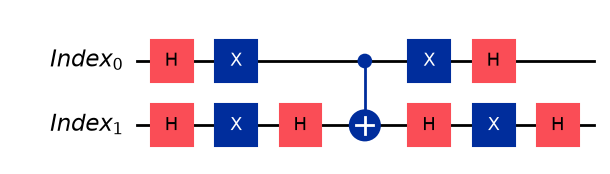

In [14]:
index_register = QuantumRegister(size=2, name="Index")
gd_circuit = QuantumCircuit(index_register)

gd_circuit.append(grover_diffuser(2), index_register[:])

display(gd_circuit.decompose().draw("mpl"))

In [15]:
grover_iteration??

Signature: grover_iteration(input_list: list[int], target: int) -> qiskit.circuit.gate.Gate
Source:   
def grover_iteration(input_list: list[int], target: int) -> Gate:
    """
    Args:
        input_list: The original set given. All the elements are assumed to be positive integers.
        target: The target sum. Assumed to be positive.
    Returns:
        A Grover iteration gate. The registers are ordered (the least significant bit first) with the index register first then the sum register.
    """
    n = len(input_list)
    total = sum(input_list)

    sum_register_length = int(np.ceil(np.log2(total + 1)))

    sum_register = QuantumRegister(size=sum_register_length, name="Sum Register")
    index_register = QuantumRegister(size=n, name="Index")

    circuit = QuantumCircuit(index_register, sum_register)

    # An iteration is simply the oracle followed by the diffuser.
    phase_oracle_gate = phase_oracle(input_list, target)
    grover_diffuser_gate = grover_diffuser(n)

    cir

Here is a small example of what it looks like:

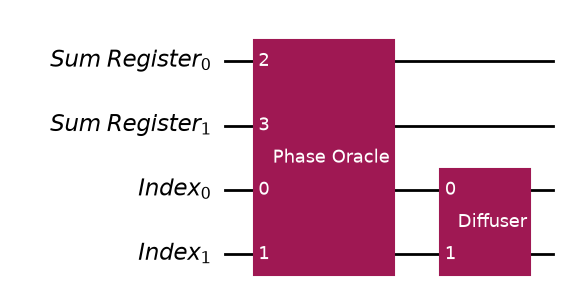

In [16]:
input_list = [1, 2]
target = 3

n = len(input_list)
total = sum(input_list)
sum_register_length = int(np.ceil(np.log2(total + 1)))
sum_register = QuantumRegister(size=sum_register_length, name="Sum Register")
index_register = QuantumRegister(size=n, name="Index")
gi_circuit = QuantumCircuit(sum_register, index_register)

gi_circuit.append(
    grover_iteration(input_list, target), index_register[:] + sum_register[:]
)

display(gi_circuit.decompose().draw("mpl"))

## Complete Circuit
Here is the implementation for constructing the entire circuit for a fixed number of Grover iterations, as well as a top level circuit diagram for a small example. Note that below the index register is initialized into equal superposition as required for Grover's algorithm.

In [17]:
build_subset_sum_circuit??

Signature:
build_subset_sum_circuit(
    input_list: list[int],
    target: int,
    number_of_iterations: int,
)
Source:   
def build_subset_sum_circuit(
    input_list: list[int], target: int, number_of_iterations: int
):
    """Constructs an entire quantum circuit to solve the subset sum problem for a fixed set and target.
    Args:
        input_list: The original set given. All the elements are assumed to be positive integers.
        target: The target sum. Assumed to be positive.
        number_of_iterations: The number of Grover iterations to be used in the circuit.
    Returns:
        A quantum circuit to solve the subset sum problem for a fixed set and target. The registers are ordered (the least significant bit first) with the index register first then the sum register.
    """
    n = len(input_list)
    total = sum(input_list)

    sum_register_length = int(np.ceil(np.log2(total + 1)))

    sum_register = QuantumRegister(size=sum_register_length, name="Sum Register")
    

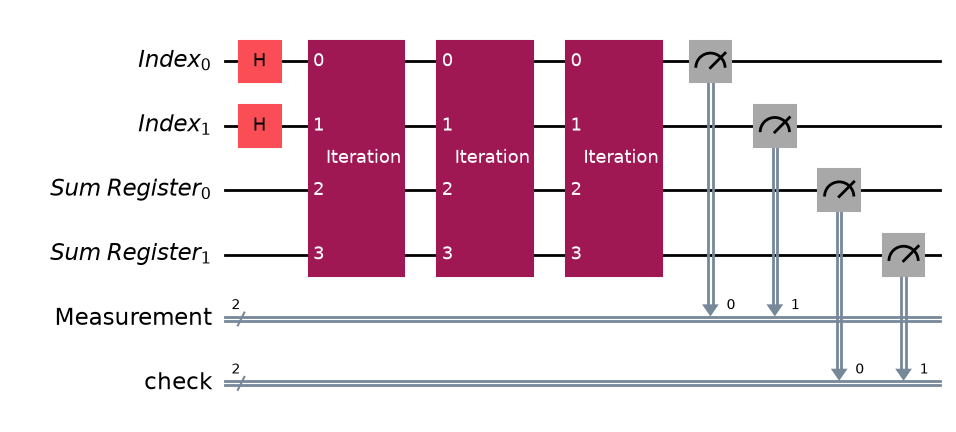

In [18]:
input_list = [1, 2]
target = 3

total_circuit = build_subset_sum_circuit(input_list, target, 3)
display(total_circuit.draw("mpl"))

## Sampling Routine
When there are only $k$ marked elements in a list, the optimal number of grover iterations is given by the nearest integer to:
$$ \frac{\pi}{4 \arcsin(\sqrt{k/N})} - \frac{1}{2}. $$

However for the subset sum problem, the number of solutions is not known in advance. In [[1]](https://people.maths.bris.ac.uk/~csxam/teaching/qc2020/lecturenotes.pdf), Montanaro outlines a simple trick to address this. They run the algorithm assuming 1 correct solution. If a correct solution is not found then they run the algorithm again assuming 2 correct solutions; then 4, 8 and so on. We implement this as follows:

In [19]:
sampling_routine??

Signature: sampling_routine(input_list: list[int], target: int)
Source:   
def sampling_routine(input_list: list[int], target: int):
    """A sampling routine to solve the subset sum problem when the number of solutions is not known in advance.
    Args:
        input_list: The original set given. All the elements are assumed to be positive integers.
        target: The target sum. Assumed to be positive.
    Returns:
        A sampling routine to solve the subset sum problem.
    """
    n = len(input_list)

    subset = []

    if sum(input_list) < target:
        print(
            f"Maximum possible sum for the input list, {sum(input_list)}, is less than the target, {target}"
        )
        return

    for i in range(n):
        number_of_iterations = compute_optimal_iterations(n, 2**i)
        circuit = build_subset_sum_circuit(input_list, target, number_of_iterations)

        sampler = StatevectorSampler()
        result = sampler.run([circuit], shots=1).result()
        dist

The helper function "compute_optimal_iterations" is shown below. It is exactly the formula shown above.

In [20]:
compute_optimal_iterations??

Signature:
compute_optimal_iterations(
    number_of_elements: int,
    number_of_solutions: int,
)
Source:   
def compute_optimal_iterations(number_of_elements: int, number_of_solutions: int):
    """Computes the optimal number of Grover iterations.
    Args:
        number_of_elements: The size of the set.
        number_of_solutions: The number of assumed solutions to our subset problem.
    Returns:
        The closest integer to np.pi / (4 * theta) - 0.5,
        where theta = arcsin(sqrt(number_of_solutions / 2^number_of_elements)
    """
    theta = np.arcsin(np.sqrt(number_of_solutions / 2**number_of_elements))
    number_of_iterations = int(np.rint(np.pi / (4 * theta) - 0.5))
    return number_of_iterations
File:      ~/Documents/Quantum Computing Bootcamp/Mini Projects/Mini Project 1/quantum-subset-sum/src/quantum_subset_sum/subset_sum.py
Type:      function

Here is an example of the sampling routine in action for the set $\{1,1,3,7\}$ and target $10$.

In [21]:
sampling_routine([1, 1, 3, 7], 10)

Found subset: [3, 7], with target sum 10


For an example where the target is in valid, i.e. greater than the sum of the entire set. It should terminate straight away given the requirements of the project. We take the set $\{1,1,1,1\}$ and target $5$.

In [22]:
sampling_routine([1, 1, 1, 1], 5)

Maximum possible sum for the input list, 4, is less than the target, 5


Finally here is an example where a subset with the target sum does not exist. We take the set $\{1,1,3,7\}$ and target $6$.

In [23]:
sampling_routine([1, 1, 3, 7], 6)

No subset found, with target sum 6, within budget


## Experiments
We simulate the probability of success as the iteration count varies. We do this for cases with 1, 4, and no solutions. We keep the number of qubits used for the index register and the sum register the same.

The code snippets for the plots below are adapted from lab 2.

### 1 Solution
We let $S= \{1, 3, 7, 9\}$ and $t=4$.

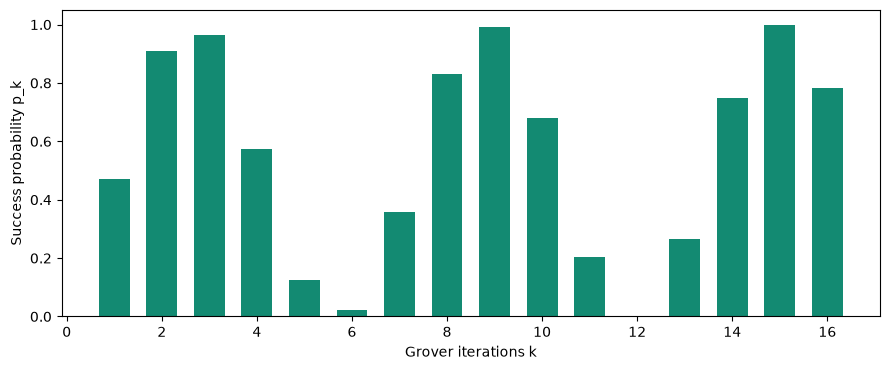

In [24]:
total_shots = 10000
correct_bitstrings = ["0011"]

S = [1, 3, 7, 9]
target = 4

probabilities = []

for i in range(2 ** len(S)):
    circuit = build_subset_sum_circuit(S, target, i + 1)
    sampler = StatevectorSampler()
    result = sampler.run([circuit], shots=total_shots).result()
    dist = result[0].data.Measurement.get_counts()
    correct_shots = 0
    for k in correct_bitstrings:
        if k in dist:
            correct_shots += dist[k]
    p = correct_shots / total_shots
    probabilities.append(p)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([i + 1 for i in range(2 ** len(S))], probabilities, width=0.65, color="#138a72")
ax.set(xlabel="Grover iterations k", ylabel="Success probability p_k", ylim=(0, 1.05))
fig.tight_layout()
plt.show()

### 4 Solutions with repeated values
We let $S= \{5, 5, 5, 5\}$ and $t=15$.

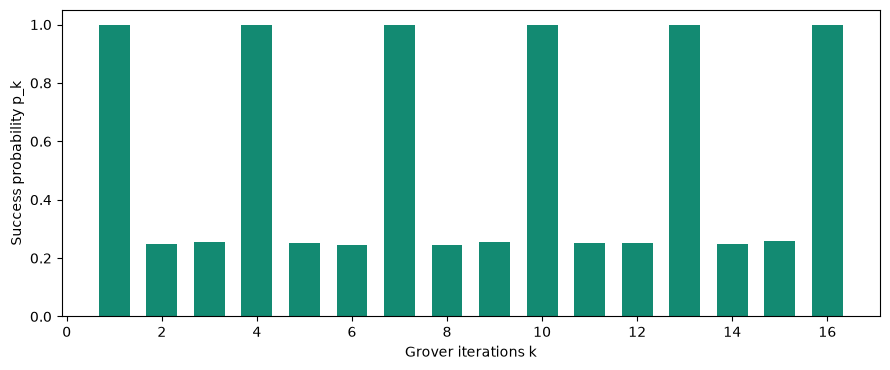

In [25]:
total_shots = 10000
correct_bitstrings = ["0111", "1011", "1101", "1110"]

S = [5, 5, 5, 5]
target = 15

probabilities = []

for i in range(2 ** len(S)):
    circuit = build_subset_sum_circuit(S, target, i + 1)
    sampler = StatevectorSampler()
    result = sampler.run([circuit], shots=total_shots).result()
    dist = result[0].data.Measurement.get_counts()
    correct_shots = 0
    for k in correct_bitstrings:
        if k in dist:
            correct_shots += dist[k]
    p = correct_shots / total_shots
    probabilities.append(p)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([i + 1 for i in range(2 ** len(S))], probabilities, width=0.65, color="#138a72")
ax.set(xlabel="Grover iterations k", ylabel="Success probability p_k", ylim=(0, 1.05))
fig.tight_layout()
plt.show()

### No Solutions
We let $S= \{1, 3, 7, 9\}$ and $t=2$. Note that the probability of success should be 0 in this case since no such subset with sum 2 exists.

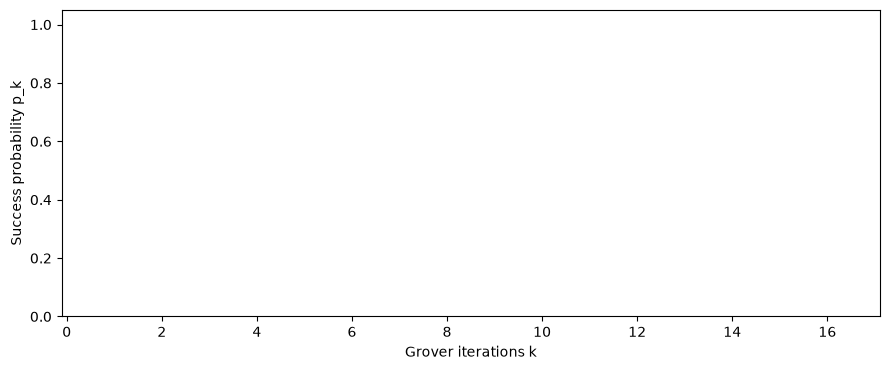

In [26]:
total_shots = 10000
correct_bitstrings = []

S = [1, 3, 7, 9]
target = 2

probabilities = []

for i in range(2 ** len(S)):
    circuit = build_subset_sum_circuit(S, target, i + 1)
    sampler = StatevectorSampler()
    result = sampler.run([circuit], shots=total_shots).result()
    dist = result[0].data.Measurement.get_counts()
    correct_shots = 0
    for k in correct_bitstrings:
        if k in dist:
            correct_shots += dist[k]
    p = correct_shots / total_shots
    probabilities.append(p)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([i + 1 for i in range(2 ** len(S))], probabilities, width=0.65, color="#138a72")
ax.set(xlabel="Grover iterations k", ylabel="Success probability p_k", ylim=(0, 1.05))
fig.tight_layout()
plt.show()

## Resource Analysis

### Ancilla Count

To stop overflow we require that the sum register has exactly
$$ a = \left\lceil \log_2 \left(1+ \sum_{x\in S} x \right) \right\rceil $$
qubits. These are the only ancilla qubits we use. Hence the total ancilla count is exactly the value above.

### Gate and Depth Count

Let $n$ be the number of elements in our set (note that this is also the number of qubits in the index register). Let $s$ be the number of qubits in the sum register. Let $d_c$ and $g_c$ denote the depth and the number of gates respectively of a given circuit $c$. Below we count multicontrolled $X$ gates as 1 gate. One could decompose these into simpler 1 or 2 qubit gates and we will touch on this in the further comments section.

We compute the gate and depth count of the Grover iteration circuit directly.

We start with the diffuser. We have the circuit when the index register has 2 qubits shown below for clarity.
$$ d_{\text{diffuser}} = 7 = O(1)$$
$$ g_{\text{diffuser}} = 4n + 3 = O(n)$$

The circuit for $n=2$ is shown below

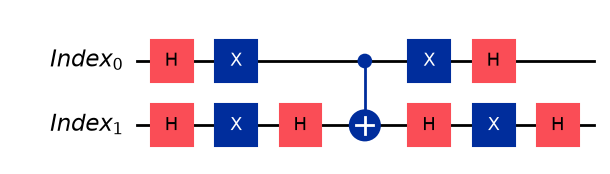

In [27]:
display(gd_circuit.decompose().draw("mpl"))

Now we consider the phase oracle. This consists of 2 controlled Draper's adders and 1 phase kickback circuit.

The phase kickback circuit is also dependent on the target due to the flip bits minicircuit. The worst case for the number of gates for that minicircuit is $s$ and the depth is always 1. Hence we deduce (look at the example below for clarity):

$$ d_{\text{phase kickback}} = 8 = O(1)$$
$$ g_{\text{phase kickback}} = 2s + 8  = O(s)$$

A circuit for $s=3$, $n=3$ is shown below.

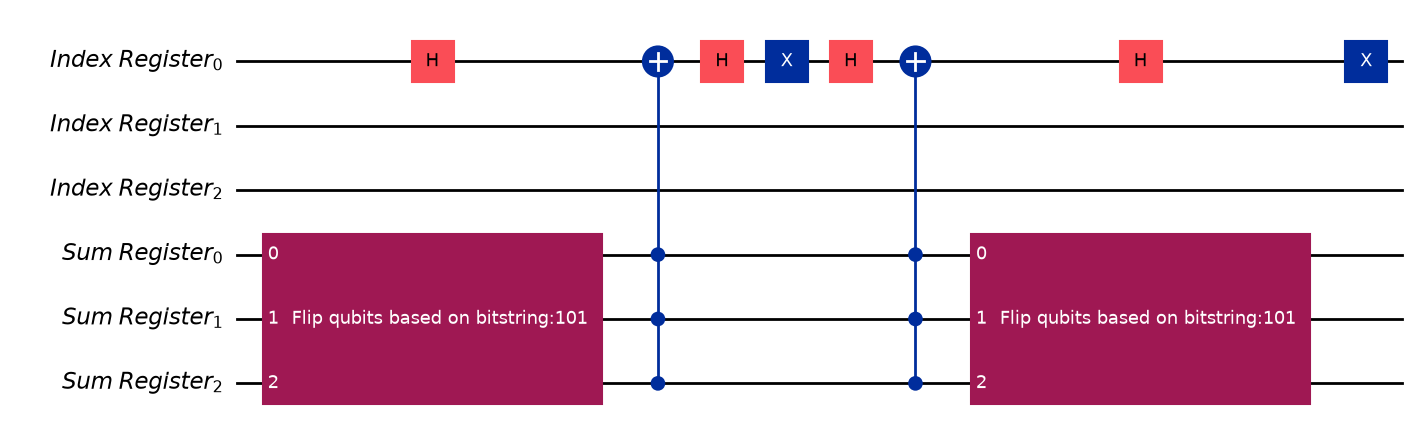

In [28]:
display(pk_circuit.decompose().draw("mpl"))

Finally we consider the controlled Draper's adder. Note that the QFT and IQFT circuits use $O(s^2)$ gates ([[2]]). The phase addition in the middle uses $sn$ controlled phase gates. Hence we deduce that:
$$ g_{\text{adder}} = O(s^2) + O(sn)$$

The depth of the QFTs for our implemention is $O(n^2)$. The depth of the phase addition is $O(sn)$. Hence we get that:

$$ d_{\text{adder}} = O(n^2) + O(sn) $$

Note that the controlled phase gates commute (they are all diagonal unitaries), hence one can rearrange the gates to actually make the depth $O(n) + O(s)$ instead. The implementation above does not do this however.

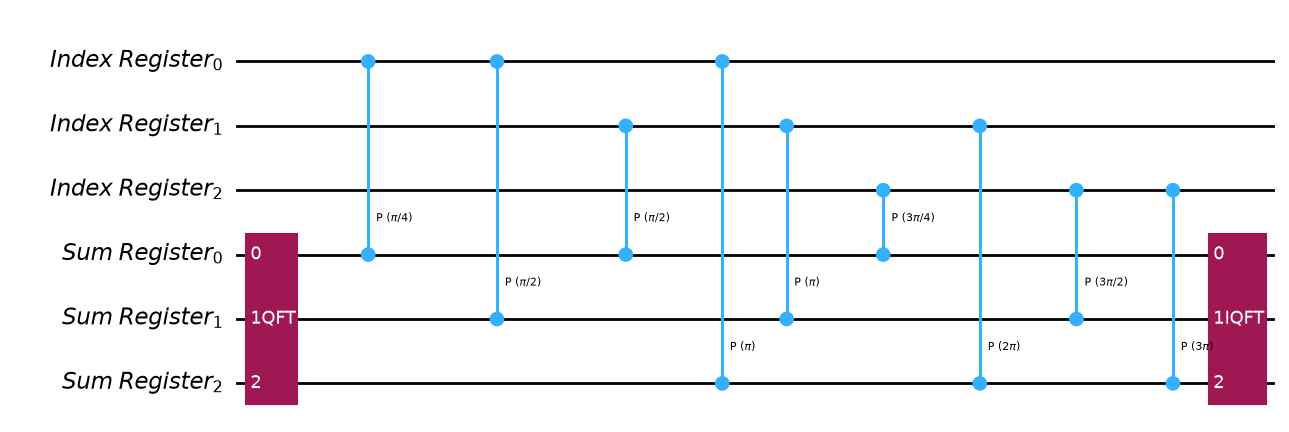

In [29]:
display(ad_circuit.decompose().draw("mpl"))

Hence we get that:
$$ d_{\text{Grover's Iteration}} = O(n^2) + O(sn),$$
$$ g_{\text{Grover's Iteration}} = O(s^2) + O(n).$$

Now given our sampling routine given above, from [[1]], we will have $O(\sqrt(n))$ Grover iterations and hence also $O(\sqrt(n))$ Oracle calls. Hence for the sampling routine we have the following gate and depth complexity:
$$ d_{\text{Sampling Routine}} = O(n^{5/2}) + O(sn^{3/2}),$$
$$ g_{\text{Sampling Routine}} = O(n^{1/2}s^2) + O(n^{3/2}).$$

## Further Extensions and Comments

1. One could optimize the Draper's adder to get a depth of $O(n) + O(s)$ instead. This is since the controlled phase gates all commute (they are all diagonal unitaries), and hence one could rearrange them to get a better depth. 
2. We counted MCX gates as 1 gate in the gate count above. But if we wanted to only restrict ourselves to 1 qubit or 2 qubit gates, the gate complexity would look a little different. Note that we use 3 MCX gates, 2 of which operate on $s+1$ qubits, and the last one operates on $n$ qubits. [[3]] gives the gate complexity of MCX gates when using 2 qubit gates for different cases dependent on how many extra ancillas we allow.

## References
<a id="1">[1]</a>
Ashley Montanaro.
[Quantum Computation Lecture Notes](https://people.maths.bris.ac.uk/~csxam/teaching/qc2020/lecturenotes.pdf)

<a id="2">[2]</a>
Nielsen, Michael A.; Chuang, Isaac L. (2012). Quantum Computation and Quantum Information.
ISBN 978-1-107-00217-3.

<a id="3">[3]</a>
https://gate.directory/gates/mcx/,
https://github.com/natestemen/gate.directory